# Figure 4: RT&T-MERFISH isoform usage in the mouse brain

Fig. 4 fits Saturn to gene expression and isoform usage measured in the same cells of a coronal section of the adult mouse
brain (RT&T-MERFISH, `ISO` file set, section 5). The panel reads about 23,000 genes and about 10,000 isoforms; 47,649 cells
are pooled into 2,721 bins of 100 um. `rho_RNA` orders the bins by expression and `rho_Isoform` by isoform usage, the share
of a gene's reads carried by each isoform.

The notebook builds the two targets, fits Saturn, calls and names domains on each axis, and draws panels b to o: the major
cell classes (b), the axes and domains (c), variance explained (d), fitted functions (e), how much of the usage change between
domains comes from cell composition (f), usage inside cell classes (g), usage change against expression change (h), the isoform
switches at the amygdala / olfactory cortex | cortex boundary (i to k), and isoform switching along an RNA state score inside
Sst interneurons (l to o). Panel a is a schematic of the assay.

**Input data:** the RT&T-MERFISH cell-by-feature matrix `cellxgene_ISO_labels.h5ad` and an Ensembl transcript-to-gene table.
Results of tools from other environments are read from `published/`.

**Conda env:** `spatialmultivelo`. **Time:** about 15 to 25 min on 8 CPU threads, most of it the fit and the permutation
tests.

## Setup

The published fit used 8 torch threads with `OMP_NUM_THREADS` unset. A CPU fit depends on the thread count as well as on the
seed, so the variable is removed before numpy and torch are imported.

In [1]:
import os
os.environ.pop("OMP_NUM_THREADS", None)
import json
from pathlib import Path

import anndata as ad
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.sparse as sp
from matplotlib.gridspec import GridSpec
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from scipy.interpolate import griddata
from scipy.optimize import minimize
from scipy.spatial import cKDTree
from scipy.stats import chi2, spearmanr
from sklearn.metrics import roc_auc_score
from statsmodels.stats.multitest import multipletests

import saturn
from saturn import piecewise as pw
from saturn.domains import isodepth_bins
from saturn.theme import ANCHOR, CELLCLASS, CMAP, DOMAIN, MODALITY

saturn.theme.set_theme(7)
C_RNA, C_ISO = MODALITY["RNA"], MODALITY["Isoform"]
INK, GREY, LIGHT, MIST, RUST = ANCHOR["ink"], ANCHOR["stone"], ANCHOR["silver"], ANCHOR["mist"], ANCHOR["rust"]

WORK = Path(os.environ.get("SATURN_WORKSPACE", "saturn_workspace"))
PUB = WORK / "published"
OUT = WORK / "results" / "fig4"
OUT.mkdir(parents=True, exist_ok=True)
DS = "rtt_merfish_s5_iso100_sv_pca_shrunk"

## Data

Features whose names start with `ENSMUST` are isoforms, the others are genes. The transcript-to-gene table gives each isoform
its gene. Each cell gets a broad class from its type label.

In [2]:
a = ad.read_h5ad(WORK / "cellxgene_ISO_labels.h5ad")
a = a[a.obs["sample"].astype(str) == "5"].copy()

is_iso = np.array([v.startswith("ENSMUST") for v in a.var_names])
tx2gene = pd.read_csv(WORK / "ensembl_tx2gene_mm.tsv", sep="\t").drop_duplicates("tx").set_index("tx")["gene"]
iso_gene = tx2gene.reindex(a.var_names[is_iso]).values
mapped = pd.notna(iso_gene)

X = sp.csr_matrix(a.X)
X_gene = X[:, np.where(~is_iso)[0]]
X_iso = X[:, np.where(is_iso)[0][mapped]].tocsc()
genes = np.array(a.var_names[~is_iso], str)
iso_gene = np.array(iso_gene[mapped], str)
iso_name = np.array([v.split(".")[0] for v in a.var_names[is_iso][mapped]])
cell_xy = a.obs[["global_x", "global_y"]].values.astype(float)
cell_type = a.obs["cell_label"].astype(str).values


def cell_class(t):
    if t in ("Oligodendrocytes", "NFOLs"): return "oligodendrocyte"
    if t == "OPCs": return "OPC"
    if t == "Astrocytes": return "astrocyte"
    if t == "Microglia": return "microglia"
    if t in ("Endothelial", "Pericytes", "SMCs", "VLMCs"): return "vascular"
    if t in ("Choroid Plexus", "Ependymal"): return "choroid/ependymal"
    if t == "Other": return "other"
    return "neuron"


cell_cls = np.array([cell_class(t) for t in cell_type])
print("cells", a.n_obs, " cell types", len(set(cell_type)), " genes", X_gene.shape[1], " isoforms with a gene", X_iso.shape[1])

cells 47649  cell types 36  genes 22930  isoforms with a gene 9749


Cells are pooled in 100 um bins, and bins with fewer than 5 cells are dropped. `G` maps cells to bins and `cell_bin` keeps the
bin of every cell (-1 outside the kept bins), because several panels go back to single cells.

In [3]:
key = np.floor(cell_xy / 100.0).astype(np.int64)
code = key[:, 0] * 1_000_000 + key[:, 1]
uniq, inv, n_cells = np.unique(code, return_inverse=True, return_counts=True)
kept = np.where(n_cells >= 5)[0]
G = sp.csr_matrix((np.ones(len(inv)), (inv, np.arange(len(inv)))), shape=(len(uniq), len(inv)))[kept]
bin_of_uniq = np.full(len(uniq), -1)
bin_of_uniq[kept] = np.arange(len(kept))
cell_bin = bin_of_uniq[inv]

counts_R = sp.csr_matrix(G @ X_gene)
counts_I = sp.csc_matrix(G @ X_iso).astype(float)
coords = np.asarray(G @ cell_xy) / n_cells[kept][:, None]
lib_R = np.asarray(counts_R.sum(1)).ravel().clip(1)
coords_z = saturn.zscore_coords(coords)
print("bins", len(coords), " median cells per bin", np.median(n_cells[kept]), " share of cells in bins", round((cell_bin >= 0).mean(), 3))

bins 2721  median cells per bin 17.0  share of cells in bins 0.992


## Isoform target

Isoforms enter the target only for genes with spatially variable usage. The selection comes from SPLISOSM (`SplisosmNP`,
HSIC-IR test, BH-adjusted p < 0.05) on these bins, run by `reproducibility/paper/scripts/rtt_isoform_multinomial.py` in its own
package; its table is read from `published/`. Within a selected gene we keep isoforms with at least 5% of the gene's reads, major
isoform first. Per bin, usage is shrunk toward the gene's section-wide usage with 2 pseudo-reads, turned into a centred
log-ratio within the gene and weighted by `1 / sqrt(J - 1)` (J isoforms in the gene); a PCA with 10 components and
`saturn.scale_target` gives the target.

In [4]:
sv_table = pd.read_csv(PUB / "sv_results.csv", index_col=0)
sv_genes = set(sv_table.index[sv_table.ir_padj < 0.05])
tot = np.asarray(counts_I.sum(0)).ravel()

blocks = {}
for g, idx in pd.Series(np.arange(len(iso_gene))).groupby(iso_gene):
    if g in sv_genes:
        idx = idx.values
        idx = idx[tot[idx] / tot[idx].sum() >= 0.05]
        blocks[g] = idx[np.argsort(-tot[idx])]

Z = []
for g, idx in blocks.items():
    C = counts_I[:, idx].toarray()
    P = (C + 2 * C.sum(0) / C.sum()) / (C.sum(1, keepdims=True) + 2)
    Z.append((np.log(P) - np.log(P).mean(1, keepdims=True)) / np.sqrt(len(idx) - 1))
Z = np.hstack(Z)
Z -= Z.mean(0)
U, s, _ = np.linalg.svd(Z, full_matrices=False)
Y_I = saturn.scale_target(U[:, :10] * s[:10], "global").astype(np.float32)
print(len(sv_table), "genes tested;", len(blocks), "with spatially variable usage;", Z.shape[1], "isoforms in the target")

3244 genes tested; 1071 with spatially variable usage; 2629 isoforms in the target


## RNA target

The RNA target is `saturn.rna_glmpc_real(counts_R, K=10)`, a Poisson GLM-PCA over 3,000 variable genes. GLM-PCA starts from an
unseeded random draw, so the call cannot give the same factors twice; we read the saved RNA target of the paper from
`published/`.

In [5]:
Y_R = np.asarray(np.load(PUB / f"targets_{DS}.npz")["Y_RNA"], np.float32)
targets, modalities = [Y_R, Y_I], ["RNA", "Isoform"]
print("RNA target", Y_R.shape, " isoform target", Y_I.shape)

RNA target (2721, 10)  isoform target (2721, 10)


## Saturn fit

Seed 42 with 8 threads. With the default settings `rho_Isoform` collapsed onto `rho_RNA`, so this fit uses no head restarts
(`n_restarts=0`), a 10 times higher cost on the cross pathways (`lam_cross=0.3`), and no refit on all bins
(`refit_all_epochs=0`; without restarts no bins are held out). The axes and the variance explained are kept in `OUT`, so a rerun
skips the fit.

In [6]:
if not (OUT / "axes.npy").exists():
    res = saturn.fit(targets, coords_z, modalities, seeds=[42], threads=8, refit_all_epochs=0, n_restarts=0, lam_cross=0.3)
    np.save(OUT / "axes.npy", res.axes)
    json.dump({m: {k: float(v) for k, v in r.items()} for m, r in res.r2.items()}, open(OUT / "r2.json", "w"), indent=1)
fit_axes = np.load(OUT / "axes.npy")
R2 = json.load(open(OUT / "r2.json"))
print(pd.DataFrame(R2).T.round(3))

          full  own_axis_only  other_axes_only
RNA      0.577          0.488            0.150
Isoform  0.486          0.457            0.067


The sign of an isodepth is arbitrary. Both axes are oriented so that they rise toward the cortex, using the excitatory marker
`Slc17a7`.

In [7]:
slc = np.log1p(counts_R[:, list(genes).index("Slc17a7")].toarray().ravel() / lib_R * 1e4)
axes = saturn.orient(fit_axes, np.c_[slc, slc])
d_R, d_I = axes[:, 0], axes[:, 1]
d = {"RNA": d_R, "Isoform": d_I}
print("Spearman rho_RNA vs rho_Isoform", round(spearmanr(d_R, d_I).statistic, 3))

Spearman rho_RNA vs rho_Isoform 0.92


## Domains

Each axis is segmented on its own targets with GASTON's dynamic programme; `choose_k` takes the elbow of the error curve (K = 4
on `rho_RNA`, K = 3 on `rho_Isoform`), and domain 0 is the low end of the axis. The names come from the three most common cell
types of each domain, printed below.

In [8]:
k_R, _ = saturn.domains.choose_k(d_R, Y_R)
k_I, _ = saturn.domains.choose_k(d_I, Y_I)
lab = {"RNA": saturn.domains.gaston_domains(d_R, Y_R, n_domains=k_R),
       "Isoform": saturn.domains.gaston_domains(d_I, Y_I, n_domains=k_I)}
lab_R, lab_I = lab["RNA"], lab["Isoform"]
NAMES = {"RNA": {0: "thalamus / hypothalamus", 1: "white matter & hippocampus", 2: "ventricle / choroid plexus", 3: "cortex"},
         "Isoform": {0: "subcortical & white matter", 1: "amygdala / olfactory cortex", 2: "cortex"}}
SHORT = {"subcortical & white matter": "subcort. & WM", "amygdala / olfactory cortex": "amyg./olf. ctx", "cortex": "cortex"}

ct_frac = pd.DataFrame((G @ pd.get_dummies(cell_type).values.astype(float)) / n_cells[kept][:, None], columns=sorted(set(cell_type)))
for m in modalities:
    for k in range(lab[m].max() + 1):
        top3 = ", ".join(f"{t} {v:.0%}" for t, v in ct_frac[lab[m] == k].mean().nlargest(3).items())
        print(f"{m} {k} {NAMES[m][k]} ({(lab[m] == k).sum()} bins): {top3}")


def dcol(m):
    return np.array([DOMAIN[NAMES[m][k]] for k in range(len(NAMES[m]))])


def map_axes(ax):
    ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([])
    for sd in ax.spines.values():
        sd.set_visible(False)

RNA 0 thalamus / hypothalamus (748 bins): Oligodendrocytes 20%, Thalamus 18%, Hypothalamus 17%
RNA 1 white matter & hippocampus (547 bins): Oligodendrocytes 27%, Astrocytes 19%, Endothelial 8%
RNA 2 ventricle / choroid plexus (377 bins): Oligodendrocytes 32%, Choroid Plexus 16%, Astrocytes 14%
RNA 3 cortex (1049 bins): Astrocytes 14%, Endothelial 10%, Cortex Subplate & Amygdalar Areas 9%
Isoform 0 subcortical & white matter (1560 bins): Oligodendrocytes 25%, Astrocytes 17%, Thalamus 10%
Isoform 1 amygdala / olfactory cortex (568 bins): Astrocytes 17%, Cortex Subplate & Amygdalar Areas 15%, Cortex Olfactory Areas 9%
Isoform 2 cortex (593 bins): Cortex L2/3 IT 12%, Astrocytes 11%, Endothelial 10%


## Fig. 4a: RT&T-AMP-MERFISH

Fig. 4a is a schematic of RT&T-AMP-MERFISH imaging individual transcript isoforms in situ; it is not drawn here.

## Fig. 4b: major cell classes

Major cell classes in the coronal section (47,649 cells; scale bar 1 mm).

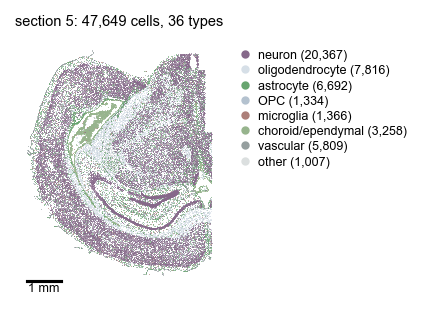

In [9]:
order = ["other", "vascular", "choroid/ependymal", "microglia", "OPC", "astrocyte", "oligodendrocyte", "neuron"]
fig, ax = plt.subplots(figsize=(3.2, 2.2))
for c in order:
    m = cell_cls == c
    ax.scatter(*cell_xy[m].T, s=0.12, lw=0, color=CELLCLASS[c], rasterized=True)
map_axes(ax)
x0, y0 = cell_xy.min(0)
ax.plot([x0, x0 + 1000], [y0 - 150] * 2, color="k", lw=1.5)
ax.text(x0 + 500, y0 - 220, "1 mm", ha="center", va="top", fontsize=6)
ax.legend(handles=[Line2D([], [], ls="", marker="o", ms=3, color=CELLCLASS[c], label=f"{c} ({(cell_cls == c).sum():,})") for c in order[::-1]],
          fontsize=6, loc="upper left", bbox_to_anchor=(1.0, 1.0), handletextpad=0.1, labelspacing=0.25)
ax.set_title(f"section 5: {len(cell_cls):,} cells, {len(set(cell_type))} types")
plt.show()

## Fig. 4c: isodepths and domains

`rho_RNA`, RNA domains, `rho_Isoform` and isoform domains (2,721 bins of 100 um), coloured by the annotated label.

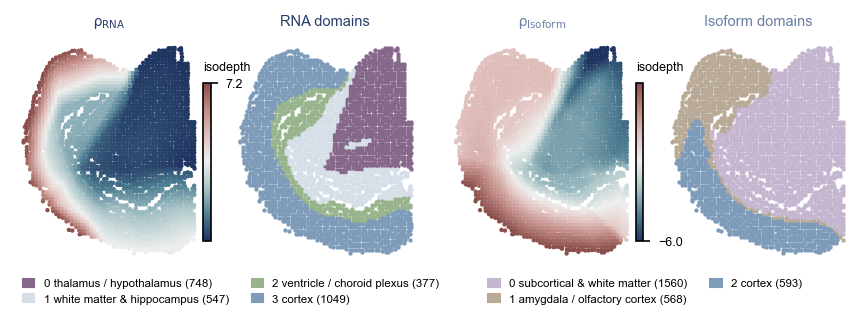

In [10]:
fig, AX = plt.subplots(1, 4, figsize=(7.2, 2.4))
for j, m in enumerate(modalities):
    lo, hi = np.percentile(d[m], [1, 99])
    sc = saturn.plotting.spatial(AX[2 * j], coords, d[m], cmap=CMAP["score"], vmin=lo, vmax=hi)
    cb = fig.colorbar(sc, cax=AX[2 * j].inset_axes([1.0, 0.1, 0.04, 0.7]), ticks=[round(lo, 1), round(hi, 1)]); cb.ax.set_title("isodepth", fontsize=6, loc="left")
    AX[2 * j].set_title(f"ρ$_{{\\mathrm{{{m}}}}}$", color=MODALITY[m])
    saturn.plotting.spatial(AX[2 * j + 1], coords, lab[m], discrete=True, colors={k: DOMAIN[NAMES[m][k]] for k in NAMES[m]})
    AX[2 * j + 1].set_title(f"{m} domains", color=MODALITY[m])
    AX[2 * j + 1].legend(handles=[Patch(color=DOMAIN[NAMES[m][k]], label=f"{k} {NAMES[m][k]} ({(lab[m] == k).sum()})") for k in NAMES[m]],
                         fontsize=5.5, loc="upper center", bbox_to_anchor=(0.0 if j == 0 else -0.1, -0.02), ncol=2, handlelength=1)
plt.subplots_adjust(wspace=0.15)
plt.show()

## Fig. 4d: variance explained

Variance explained (R²) of the RNA and isoform inputs by the full model, the own axis and the cross axis.

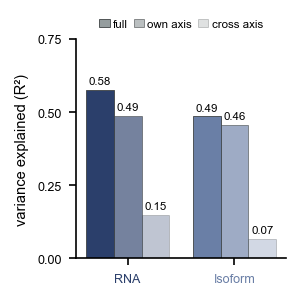

In [11]:
fig, ax = plt.subplots(figsize=(1.8, 1.9))
x, w = np.arange(2), 0.26
for i, (k_, alpha) in enumerate([("full", 1.0), ("own_axis_only", 0.65), ("other_axes_only", 0.3)]):
    v = [R2[m][k_] for m in modalities]
    ax.bar(x + (i - 1) * w, v, w, color=[MODALITY[m] for m in modalities], alpha=alpha, edgecolor=INK, lw=0.4)
    for xx, vv in zip(x + (i - 1) * w, v):
        ax.text(xx, vv + 0.012, f"{vv:.2f}", ha="center", va="bottom", fontsize=5.5)
ax.set_xticks(x); ax.set_xticklabels(modalities)
for tl, m in zip(ax.get_xticklabels(), modalities):
    tl.set_color(MODALITY[m])
ax.set_ylim(0, 0.75); ax.set_yticks([0, 0.25, 0.5, 0.75]); ax.set_ylabel("variance explained (R²)")
ax.legend(handles=[Patch(fc=GREY, alpha=a_, ec=INK, lw=0.4, label=l_) for a_, l_ in [(1, "full"), (0.65, "own axis"), (0.3, "cross axis")]],
          fontsize=5.5, loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=3, handlelength=0.9, columnspacing=0.5, handletextpad=0.3)
plt.show()

## Fig. 4e: fitted functions

Each feature is shown as the observed value per bin, the fitted piecewise function at every bin, and bin means with the fitted
function along the own axis. Genes follow `rho_RNA` with GASTON's per-domain Poisson fit (`saturn.piecewise.fit_poisson`, 25 equal
width bins, R² on the rate scale); isoform usage follows `rho_Isoform` with the binomial fit (`fit_binomial`, 30 bins, reads of
the isoform out of reads of all isoforms of the gene). A domain keeps its slope only when the likelihood-ratio p < 0.1.

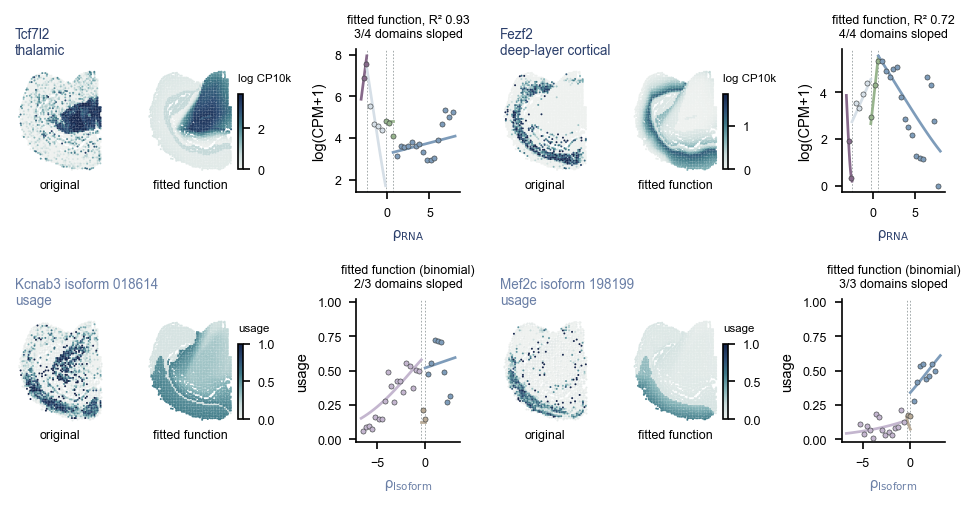

{"Tcf7l2": {"R2": 0.927, "n_sloped": 3}, "Fezf2": {"R2": 0.717, "n_sloped": 4}, "Kcnab3": {"isoform": "ENSMUST00000018614", "n_sloped": 2, "reads": 5339}, "Mef2c": {"isoform": "ENSMUST00000198199", "n_sloped": 3, "reads": 5025}}


In [12]:
def along(ax, m, db, ob, lb, nb_ok, curve):
    dm, lm, cl = d[m], lab[m], dcol(m)
    for k in range(lm.max() + 1):
        s_ = (lb == k) & nb_ok
        ax.scatter(db[s_], ob[s_], s=6, color=cl[k], lw=0.3, edgecolor=INK, zorder=3)
        xs = np.linspace(dm[lm == k].min(), dm[lm == k].max(), 20)
        ax.plot(xs, curve(k, xs), color=cl[k], lw=1.3, zorder=2)
    for b in sorted([dm[lm == k].max() for k in range(lm.max() + 1)])[:-1]:
        ax.axvline(b, color=GREY, lw=0.4, ls=(0, (2, 2)), zorder=1)
    ax.set_xlabel(f"ρ$_{{\\mathrm{{{m}}}}}$", color=MODALITY[m])


def binned(m, nb, num, den):
    bi, _, kp = isodepth_bins(d[m], nb)
    db = np.array([d[m][bi == b].mean() for b in kp])
    lb = np.array([np.bincount(lab[m][bi == b], minlength=lab[m].max() + 1).argmax() for b in kp])
    return db, np.array([num[bi == b].sum() for b in kp]), np.array([den[bi == b].sum() for b in kp]), lb


def gene_feature(ax3, g, sub):
    c = counts_R[:, list(genes).index(g)].toarray().ravel().astype(float)
    sl, it = (v[0] for v in pw.fit_poisson(c[:, None], lib_R, lab_R, d_R, t=0.1))
    db, cb_, lbin, lb = binned("RNA", 25, c, lib_R)
    y = cb_ / np.maximum(lbin, 1)
    r2 = 1 - ((y - np.exp(it[lb] + sl[lb] * db)) ** 2).sum() / ((y - y.mean()) ** 2).sum()
    obs, fit = np.log1p(c / lib_R * 1e4), np.log1p(np.exp(it[lab_R] + sl[lab_R] * d_R) * 1e4)
    along(ax3[2], "RNA", db, np.log1p(y * 1e6), lb, np.ones(len(db), bool), lambda k, xs: np.log1p(np.exp(it[k] + sl[k] * xs) * 1e6))
    ax3[2].set_ylabel("log(CPM+1)")
    k = int((np.abs(sl) > 1e-9).sum())
    ax3[2].set_title(f"fitted function, R² {r2:.2f}\n{k}/{len(sl)} domains sloped", fontsize=6)
    return obs, fit, "log CP10k", f"{g}\n{sub}", C_RNA, dict(R2=round(float(r2), 3), n_sloped=k)


def iso_feature(ax3, g, iso):
    s_ = counts_I[:, np.where(iso_name == iso)[0][0]].toarray().ravel()
    n_ = np.asarray(counts_I[:, np.where(iso_gene == g)[0]].sum(1)).ravel()
    sl, it = (v[0] for v in pw.fit_binomial(s_[:, None], n_, lab_I, d_I, t=0.1))
    db, sb, nb_, lb = binned("Isoform", 30, s_, n_)
    along(ax3[2], "Isoform", db, sb / np.maximum(nb_, 1), lb, nb_ >= 20, lambda k, xs: 1 / (1 + np.exp(-(it[k] + sl[k] * xs))))
    ax3[2].set_ylim(-0.02, 1.02); ax3[2].set_ylabel("usage")
    k = int((np.abs(sl) > 1e-12).sum())
    ax3[2].set_title(f"fitted function (binomial)\n{k}/{len(sl)} domains sloped", fontsize=6)
    obs = np.where(n_ > 0, s_ / np.maximum(n_, 1), np.nan)
    return obs, 1 / (1 + np.exp(-(it[lab_I] + sl[lab_I] * d_I))), "usage", f"{g} isoform {iso[-6:]}\nusage", C_ISO, \
        dict(isoform=iso, n_sloped=k, reads=int(s_.sum()))


FEATURES = [(gene_feature, "Tcf7l2", "thalamic"), (gene_feature, "Fezf2", "deep-layer cortical"),
            (iso_feature, "Kcnab3", "ENSMUST00000018614"), (iso_feature, "Mef2c", "ENSMUST00000198199")]
fig, AX = plt.subplots(2, 8, figsize=(8.0, 3.4), gridspec_kw=dict(width_ratios=[1, 1, 0.45, 1.15] * 2, wspace=0.5, hspace=0.75))
for a_ in AX[:, [2, 6]].ravel():
    a_.set_axis_off()
feat_stats = {}
for i, (fn, g, extra) in enumerate(FEATURES):
    ax3 = AX[i // 2, [4 * (i % 2), 4 * (i % 2) + 1, 4 * (i % 2) + 3]]
    obs, fit, unit, title, col, feat_stats[g] = fn(ax3, g, extra)
    ok = np.isfinite(obs)
    lo, hi = (0, 1) if unit == "usage" else np.nanpercentile(np.r_[obs, fit], [2, 99])
    o = np.argsort(np.where(ok, obs, -1))
    ax3[0].scatter(*coords[~ok].T, s=0.9, lw=0, color=MIST, rasterized=True)
    ax3[0].scatter(*coords[o][ok[o]].T, c=obs[o][ok[o]], cmap=CMAP["expression"], vmin=lo, vmax=hi, s=0.9, lw=0, rasterized=True)
    sc = ax3[1].scatter(*coords.T, c=fit, cmap=CMAP["expression"], vmin=lo, vmax=hi, s=0.9, lw=0, rasterized=True)
    cb = fig.colorbar(sc, cax=ax3[1].inset_axes([1.03, 0.05, 0.06, 0.7])); cb.ax.set_title(unit, fontsize=5.5, loc="left")
    for a_, t_ in zip(ax3[:2], ("original", "fitted function")):
        map_axes(a_); a_.text(0.5, -0.04, t_, transform=a_.transAxes, ha="center", va="top", fontsize=6)
    ax3[0].set_title(title, color=col, loc="left", fontsize=6.5)
plt.show()
print(json.dumps(feat_stats))

## Isoform usage per bin

For the analyses below, every non-major isoform of the selected genes is a binomial feature: `A` holds its reads per bin and `N`
the reads of its gene. `binom_irls` is a batched binomial GLM fitted by IRLS over the columns of `A`; the design can be shared or
differ per column. The package has no batched GLM, so it is written out here.

In [13]:
pairs = [(g, j, idx) for g, idx in blocks.items() for j in idx[1:]]
A = counts_I[:, [j for _, j, _ in pairs]].toarray()
N = np.column_stack([np.asarray(counts_I[:, idx].sum(1)).ravel() for *_, idx in pairs])
pair_gene = np.array([g for g, *_ in pairs])
pair_iso = iso_name[[j for _, j, _ in pairs]]
depth_I = np.asarray(counts_I.sum(1)).ravel()


def binom_irls(A, N, X, iters=25, ridge=1e-6):
    """batched binomial GLM. A, N: (n, I); X: (n, p) shared or (I, n, p). Returns coefficients (I, p) and deviance (I,)."""
    Xb = np.broadcast_to(X, (A.shape[1],) + X.shape) if X.ndim == 2 else X
    p0 = np.clip(A.sum(0) / np.maximum(N.sum(0), 1), 1e-4, 1 - 1e-4)
    B = np.zeros((A.shape[1], Xb.shape[2])); B[:, 0] = np.log(p0 / (1 - p0))
    for _ in range(iters):
        eta = np.einsum("ibp,ip->bi", Xb, B); p = 1 / (1 + np.exp(-np.clip(eta, -30, 30)))
        W = N * p * (1 - p); z = eta + (A - N * p) / np.maximum(W, 1e-9)
        XtWX = np.einsum("ibp,bi,ibq->ipq", Xb, W, Xb) + ridge * np.eye(Xb.shape[2])
        Bn = np.linalg.solve(XtWX, np.einsum("ibp,bi->ip", Xb, W * z)[..., None])[..., 0]
        done = np.max(np.abs(Bn - B)) < 1e-7
        B = Bn
        if done:
            break
    eta = np.einsum("ibp,ip->bi", Xb, B); p = np.clip(1 / (1 + np.exp(-np.clip(eta, -30, 30))), 1e-12, 1 - 1e-12)
    return B, -2 * (A * np.log(p) + (N - A) * np.log(1 - p)).sum(0)


zs = lambda v: (v - v.mean()) / v.std()
one = np.ones(len(d_I))
ld = zs(np.log(depth_I.clip(1)))
_, dev_i = binom_irls(A, N, np.c_[one, zs(d_I), ld])
_, dev_r = binom_irls(A, N, np.c_[one, zs(d_R), ld])
_, dev_0 = binom_irls(A, N, np.c_[one, ld])
screen = pd.DataFrame(dict(gene=pair_gene, isoform=pair_iso, reads=A.sum(0), dev_expl_iso=1 - dev_i / dev_0, dev_expl_rna=1 - dev_r / dev_0))
print(len(screen), "isoforms; rho_Isoform explains more deviance than rho_RNA for", round((screen.dev_expl_iso > screen.dev_expl_rna).mean(), 3))

1558 isoforms; rho_Isoform explains more deviance than rho_RNA for 0.565


## Fig. 4f: composition or within cell type

For the 40 isoforms with at least 200 reads whose usage follows `rho_Isoform` most (deviance explained, binomial GLM with log
depth), we take the two `rho_Isoform` domains of lowest and highest usage and split the change of usage between them into a
composition part and a within-cell-type part (Kitagawa decomposition on single cells). The 95% interval of the within part comes
from 300 bootstraps of cells inside each cell type and domain.

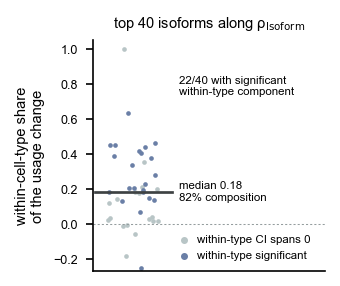

In [14]:
types, ct_code = np.unique(cell_type, return_inverse=True)
cell_dom = np.where(cell_bin >= 0, lab_I[cell_bin.clip(0)], -1)


def kitagawa(a_, t_, f, c):
    """usage change from cells f to cells c, split into composition and within-type parts"""
    af, nf = np.bincount(ct_code[f], a_[f], len(types)), np.bincount(ct_code[f], t_[f], len(types))
    ac, nc = np.bincount(ct_code[c], a_[c], len(types)), np.bincount(ct_code[c], t_[c], len(types))
    pooled = (af + ac) / np.maximum(nf + nc, 1)
    uf, uc = np.where(nf > 0, af / np.maximum(nf, 1), pooled), np.where(nc > 0, ac / np.maximum(nc, 1), pooled)
    wf, wc = nf / max(nf.sum(), 1), nc / max(nc.sum(), 1)
    return ((wc - wf) * (uc + uf) / 2).sum(), ((wc + wf) / 2 * (uc - uf)).sum()


def cell_usage(gene, isoform):
    t_ = np.asarray(X_iso[:, np.where(iso_gene == gene)[0]].sum(1)).ravel()
    a_ = X_iso[:, np.where(iso_name == isoform)[0][0]].toarray().ravel()
    return a_, t_


def split(a_, t_, k_from, k_to, rng, nboot=300):
    f, c = np.where(cell_dom == k_from)[0], np.where(cell_dom == k_to)[0]
    comp, within = kitagawa(a_, t_, f, c)
    in_f = [v for v in (f[ct_code[f] == t] for t in range(len(types))) if len(v)]
    in_c = [v for v in (c[ct_code[c] == t] for t in range(len(types))) if len(v)]
    boot = [kitagawa(a_, t_, np.concatenate([rng.choice(v, len(v)) for v in in_f]), np.concatenate([rng.choice(v, len(v)) for v in in_c]))[1]
            for _ in range(nboot)]
    return dict(composition=comp, within=within, within_ci_lo=np.percentile(boot, 2.5), within_ci_hi=np.percentile(boot, 97.5))


rng = np.random.default_rng(0)
rows = []
for _, r in screen[screen.reads >= 200].sort_values("dev_expl_iso", ascending=False).head(40).iterrows():
    a_, t_ = cell_usage(r.gene, r.isoform)
    u = [a_[cell_dom == k].sum() / max(t_[cell_dom == k].sum(), 1) if t_[cell_dom == k].sum() >= 50 else np.nan for k in range(lab_I.max() + 1)]
    if np.sum(np.isfinite(u)) < 2:
        continue
    S_ = split(a_, t_, int(np.nanargmin(u)), int(np.nanargmax(u)), rng)
    rows.append(dict(gene=r.gene, isoform=r.isoform, **S_))
whole = pd.DataFrame(rows)
whole["within_frac"] = whole.within / (whole.composition + whole.within)
whole["within_sig"] = (whole.within_ci_lo > 0) | (whole.within_ci_hi < 0)

fig, ax = plt.subplots(figsize=(2.0, 2.0))
v = whole.within_frac.clip(-0.25, 1.0).values; sig = whole.within_sig.values
xj = np.random.default_rng(0).uniform(-0.25, 0.25, len(v))
ax.scatter(xj[~sig], v[~sig], s=5, lw=0, color=LIGHT, label="within-type CI spans 0")
ax.scatter(xj[sig], v[sig], s=5, lw=0, color=C_ISO, label="within-type significant")
med = float(np.median(whole.within_frac))
ax.plot([-0.38, 0.38], [med, med], color=INK, lw=1.3)
ax.axhline(0, color=GREY, lw=0.5, ls=(0, (2, 2)))
ax.set_xlim(-0.4, 1.9); ax.set_xticks([]); ax.set_ylim(-0.27, 1.05)
ax.set_ylabel("within-cell-type share\nof the usage change")
ax.text(0.45, med, f"median {med:.2f}\n{100 * (1 - med):.0f}% composition", fontsize=5.5, va="center")
ax.text(0.45, 0.85, f"{int(sig.sum())}/{len(whole)} with significant\nwithin-type component", fontsize=5.5, va="top")
ax.legend(fontsize=5.5, loc="lower left", bbox_to_anchor=(0.3, 0.0), handletextpad=0.1, markerscale=1.5)
ax.set_title(f"top {len(whole)} isoforms along ρ$_{{\\mathrm{{Isoform}}}}$")
plt.show()

## Fig. 4g: usage along rho_Isoform inside cell classes

Usage of Lamp5 143777, Mef2c 198199 and Kcnab3 018614 in single cells, in all cells and within four cell classes: usage in sextiles of `rho_Isoform` (of each cell's
bin) with a 95% bootstrap interval. The slope per SD of `rho` is a binomial GLM per class, tested against 200 rotations of the
`rho_Isoform` map (each rotated map re-read at the nearest bin keeps its spatial autocorrelation but loses its alignment).

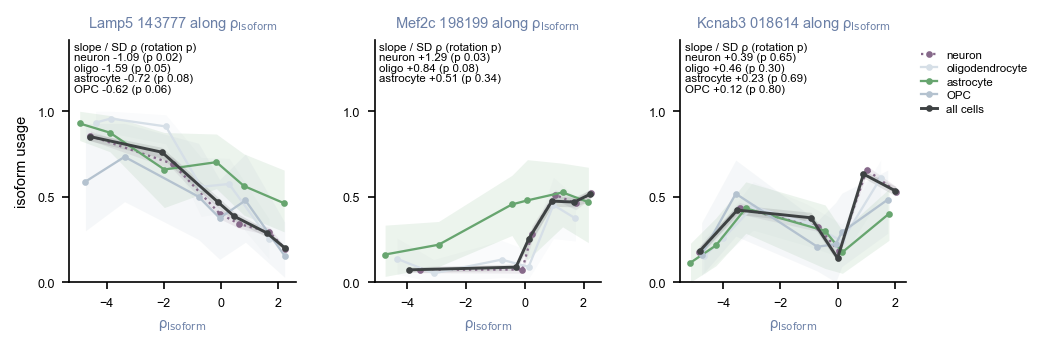

In [15]:
CLASSES = ["neuron", "oligodendrocyte", "astrocyte", "OPC"]
RHO_EX = [("Lamp5", "ENSMUST00000143777"), ("Mef2c", "ENSMUST00000198199"), ("Kcnab3", "ENSMUST00000018614")]
NQ = 6

rrot = np.random.default_rng(1); c0 = coords.mean(0); rot = []
for _ in range(200):
    th = rrot.uniform(0, 2 * np.pi)
    Rm = np.array([[np.cos(th), -np.sin(th)], [np.sin(th), np.cos(th)]])
    rot.append(griddata((coords - c0) @ Rm.T + c0, d_I, coords, method="nearest"))
rot = np.array(rot)


def per_class(gene, iso):
    """slope per SD of rho_Isoform and its rotation p, per cell class"""
    a_, t_ = cell_usage(gene, iso)
    ok = (cell_bin >= 0) & (t_ > 0); sd = d_I.std(); st = {}
    for cls in CLASSES + ["all cells"]:
        idx = np.where(ok & ((cell_cls == cls) if cls != "all cells" else True))[0]
        if t_[idx].sum() < 100:
            continue
        x = d_I[cell_bin[idx]]; A_, N_ = a_[idx].astype(float), t_[idx].astype(float)
        b1 = binom_irls(A_[:, None], N_[:, None], np.c_[np.ones_like(x), (x - x.mean()) / sd])[0][0, 1]
        Rn = rot[:, cell_bin[idx]].T; Rn = (Rn - Rn.mean(0)) / sd
        nl = binom_irls(np.repeat(A_[:, None], len(rot), 1), np.repeat(N_[:, None], len(rot), 1),
                        np.stack([np.c_[np.ones(len(x)), Rn[:, k]] for k in range(len(rot))]))[0][:, 1]
        st[cls] = dict(idx=idx, slope_per_sd=b1, p_rot=((np.abs(nl) >= abs(b1)).sum() + 1) / (len(rot) + 1))
    return a_, t_, st


rng = np.random.default_rng(0)
fig, AX = plt.subplots(1, 3, figsize=(7.2, 2.1), gridspec_kw=dict(wspace=0.35))
for i, (g, iso) in enumerate(RHO_EX):
    ax = AX[i]; a_, t_, st = per_class(g, iso)
    for cls in CLASSES + ["all cells"]:
        if cls not in st:
            continue
        idx = st[cls]["idx"]; x = d_I[cell_bin[idx]]; A_, N_ = a_[idx].astype(float), t_[idx].astype(float)
        q = np.quantile(x, np.linspace(0, 1, NQ + 1)); bi = np.clip(np.digitize(x, q[1:-1]), 0, NQ - 1); xb, yb, lo, hi = [], [], [], []
        for b in range(NQ):
            mb = np.where(bi == b)[0]
            if N_[mb].sum() < 10:
                continue
            bs = [A_[s_].sum() / max(N_[s_].sum(), 1) for s_ in (rng.choice(mb, len(mb)) for _ in range(200))]
            xb.append(x[mb].mean()); yb.append(A_[mb].sum() / N_[mb].sum()); lo.append(np.percentile(bs, 2.5)); hi.append(np.percentile(bs, 97.5))
        col = INK if cls == "all cells" else CELLCLASS[cls]
        ax.fill_between(xb, lo, hi, color=col, alpha=0.12, lw=0)
        ax.plot(xb, yb, color=col, lw=1.4 if cls == "all cells" else 1.1, ls=":" if cls == "neuron" else "-", marker="o", ms=2.2, label=cls)
    ax.set_ylim(0, 1.42); ax.set_yticks([0, 0.5, 1.0]); ax.set_xlabel("ρ$_{\\mathrm{Isoform}}$", color=C_ISO)
    if i == 0:
        ax.set_ylabel("isoform usage")
    ax.set_title(f"{g} {iso[-6:]} along ρ$_{{\\mathrm{{Isoform}}}}$", color=C_ISO)
    txt = "\n".join(f"{'oligo' if c == 'oligodendrocyte' else c} {st[c]['slope_per_sd']:+.2f} (p {st[c]['p_rot']:.2f})" for c in CLASSES if c in st)
    ax.text(0.02, 0.99, "slope / SD ρ (rotation p)\n" + txt, transform=ax.transAxes, va="top", fontsize=5.5, linespacing=1.05)
AX[-1].legend(fontsize=5.5, loc="upper left", bbox_to_anchor=(1.02, 1.0), handlelength=1.4, labelspacing=0.3)
plt.show()

## Fig. 4h: usage change against expression change

Inside each `rho_Isoform` domain, usage of every non-major isoform is fitted along `rho` with a binomial GLM, and the gene's
expression with a Poisson GLM (library = all gene counts of the bin). The gate is a quasi-likelihood ratio test (likelihood ratio
divided by the Pearson dispersion of the sloped fit), BH-adjusted within the domain. Usage is sloped at q < 0.05 with a change of
at least 0.15 across the domain (2nd to 98th percentile of `rho`); expression is flat at q >= 0.05 or |log2 fold change| < 0.5.
An isoform-only change is sloped usage with flat expression. Only isoforms with >= 50 gene reads in the domain, a gene on the
expression panel and >= 20 expression counts are drawn.

        tested  usage_sloped  expr_flat  isoform_only
domain                                               
0         1556           287        477            67
1         1514           398        335            61
2         1509            70        705            24


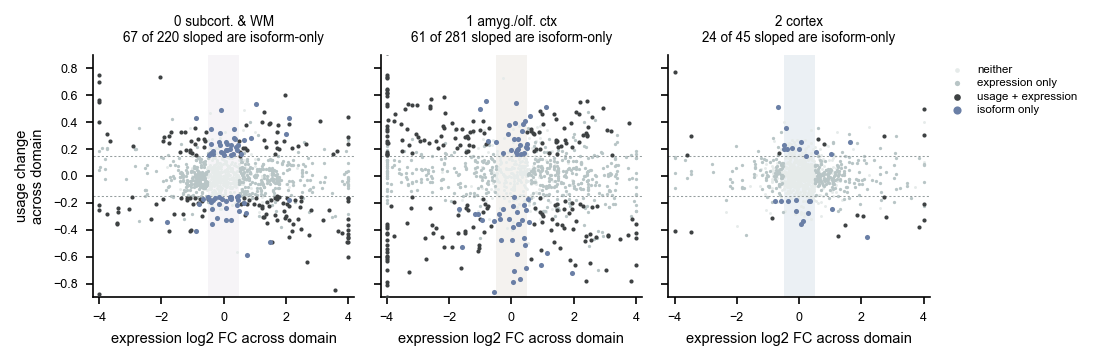

In [16]:
def glm(A, N, X, fam="binom", off=None, iters=30, ridge=1e-8):
    """batched binomial or Poisson GLM by IRLS: coefficients, log-likelihood, Pearson statistic per observation"""
    o = np.zeros(len(X)) if off is None else off
    B = np.zeros((A.shape[1], X.shape[1]))
    if fam == "binom":
        p0 = np.clip(A.sum(0) / np.maximum(N.sum(0), 1), 1e-5, 1 - 1e-5); B[:, 0] = np.log(p0 / (1 - p0))
    else:
        B[:, 0] = np.log(np.maximum(A.sum(0), 0.5) / np.exp(o).sum())
    for _ in range(iters):
        eta = X @ B.T + o[:, None]
        if fam == "binom":
            mu = 1 / (1 + np.exp(-np.clip(eta, -30, 30))); W = N * mu * (1 - mu)
            z = eta - o[:, None] + (A - N * mu) / np.maximum(W, 1e-9)
        else:
            mu = np.exp(np.clip(eta, -30, 30)); W = mu
            z = eta - o[:, None] + (A - mu) / np.maximum(mu, 1e-9)
        XtWX = np.einsum("bp,bi,bq->ipq", X, W, X) + ridge * np.eye(X.shape[1])
        B = np.linalg.solve(XtWX, np.einsum("bp,bi->ip", X, W * z)[..., None])[..., 0]
    eta = X @ B.T + o[:, None]
    if fam == "binom":
        mu = np.clip(1 / (1 + np.exp(-np.clip(eta, -30, 30))), 1e-9, 1 - 1e-9)
        ll = (A * np.log(mu) + (N - A) * np.log(1 - mu)).sum(0)
        pr = np.where(N > 0, (A - N * mu) ** 2 / np.maximum(N * mu * (1 - mu), 1e-9), 0)
    else:
        mu = np.exp(np.clip(eta, -30, 30)); ll = (A * np.log(np.maximum(mu, 1e-300)) - mu).sum(0)
        pr = (A - mu) ** 2 / np.maximum(mu, 1e-9)
    return B, ll, pr


def quasi_fit(A, N, x, fam, off=None):
    """one predictor: coefficients and the quasi-likelihood p value of the slope"""
    X_ = np.c_[np.ones_like(x), x]
    B, ll1, pr = glm(A, N, X_, fam, off)
    _, ll0, _ = glm(A, N, X_[:, :1], fam, off)
    nobs = (N > 0).sum(0) if fam == "binom" else np.full(A.shape[1], len(x))
    phi = np.maximum(pr.sum(0) / np.maximum(nobs - 2, 1), 1.0)
    return B, chi2.sf(np.maximum(2 * (ll1 - ll0), 0) / phi, 1)


sigmoid = lambda v: 1 / (1 + np.exp(-v))
gene_col = pd.Index(genes).get_indexer(pair_gene)
on_panel = gene_col >= 0
E = np.zeros_like(A)
E[:, on_panel] = counts_R[:, gene_col[on_panel]].toarray()

tables = []
for k in range(lab_I.max() + 1):
    m = lab_I == k
    x = d_I[m]; lo, hi = np.percentile(x, [2, 98]); xc = x - x.mean()
    bu, pu = quasi_fit(A[m], N[m], xc, "binom")
    be, pe = quasi_fit(E[m], None, xc, "pois", off=np.log(lib_R[m]))
    T = pd.DataFrame(dict(gene=pair_gene, isoform=pair_iso, domain=k, gene_reads=N[m].sum(0), usage=A[m].sum(0) / np.maximum(N[m].sum(0), 1),
                          usage_du=sigmoid(bu[:, 0] + bu[:, 1] * (hi - x.mean())) - sigmoid(bu[:, 0] + bu[:, 1] * (lo - x.mean())),
                          usage_p=pu, expr_counts=E[m].sum(0), expr_log2fc=be[:, 1] * (hi - lo) / np.log(2), expr_p=pe, gene_on_panel=on_panel))
    ok = T.gene_reads >= 50
    T["usage_q"] = np.nan; T.loc[ok, "usage_q"] = multipletests(T.usage_p[ok], method="fdr_bh")[1]
    okE = ok & T.gene_on_panel & (T.expr_counts >= 20)
    T["expr_q"] = np.nan; T.loc[okE, "expr_q"] = multipletests(T.expr_p[okE], method="fdr_bh")[1]
    T["usage_sloped"] = (T.usage_q < 0.05) & (T.usage_du.abs() >= 0.15)
    T["expr_flat"] = okE & ((T.expr_q >= 0.05) | (T.expr_log2fc.abs() < 0.5))
    T["isoform_only"] = T.usage_sloped & T.expr_flat
    tables.append(T)
slopes = pd.concat(tables, ignore_index=True)
print(slopes[slopes.gene_reads >= 50].groupby("domain").agg(tested=("isoform", "size"), usage_sloped=("usage_sloped", "sum"),
                                                            expr_flat=("expr_flat", "sum"), isoform_only=("isoform_only", "sum")))

shown = slopes[(slopes.gene_reads >= 50) & slopes.gene_on_panel & (slopes.expr_counts >= 20)]
fig, AX = plt.subplots(1, 3, figsize=(7.2, 2.1), sharey=True, gridspec_kw=dict(wspace=0.1))
for k, ax in enumerate(AX):
    t = shown[shown.domain == k]
    cat = np.where(t.isoform_only, "isoform only", np.where(t.usage_sloped, "usage + expression", np.where(~t.expr_flat, "expression only", "neither")))
    for c, col, sz, z in (("neither", MIST, 2, 1), ("expression only", LIGHT, 2.5, 2), ("usage + expression", INK, 4, 3), ("isoform only", C_ISO, 6, 4)):
        ax.scatter(t.expr_log2fc[cat == c].clip(-4, 4), t.usage_du[cat == c], s=sz, lw=0, color=col, zorder=z, rasterized=True, label=c)
    ax.axvspan(-0.5, 0.5, color=DOMAIN[NAMES["Isoform"][k]], alpha=0.15, lw=0, zorder=0)
    for yy in (0.15, -0.15):
        ax.axhline(yy, color=GREY, lw=0.5, ls=(0, (2, 2)))
    ax.set_xlim(-4.2, 4.2); ax.set_ylim(-0.9, 0.9)
    ax.set_xlabel("expression log2 FC across domain")
    ax.set_title(f"{k} {SHORT[NAMES['Isoform'][k]]}\n{int(t.isoform_only.sum())} of {int(t.usage_sloped.sum())} sloped are isoform-only", fontsize=6.5)
AX[0].set_ylabel("usage change\nacross domain")
AX[-1].legend(fontsize=5.5, loc="upper left", bbox_to_anchor=(1.02, 1.0), markerscale=1.6, labelspacing=0.3)
plt.show()

## Isoform switches at the amygdala / olfactory cortex | cortex boundary

The two highest `rho_Isoform` domains lie next to each other along the axis. Per isoform we take the pooled usage on each side
and the usage fitted at the boundary from each side. An isoform switches if both sides have at least 100 gene reads and either
the dominant isoform flips (usage on opposite sides of 0.5) or usage changes by at least 0.2. For the top 30 switches the change
is split into composition and within cell type as in panel f (300 bootstraps), and usage is also computed in neurons alone.

In [17]:
KA, KC = lab_I.max() - 1, lab_I.max()
ma, mc = lab_I == KA, lab_I == KC
Ta, Tc = slopes[slopes.domain == KA].reset_index(drop=True), slopes[slopes.domain == KC].reset_index(drop=True)
S = pd.DataFrame(dict(gene=pair_gene, isoform=pair_iso, reads_2=N[ma].sum(0), reads_3=N[mc].sum(0), usage_2=Ta.usage, usage_3=Tc.usage,
                      change=Tc.usage - Ta.usage))
enough = (S.reads_2 >= 100) & (S.reads_3 >= 100)
S["flip"] = enough & (np.sign(S.usage_2 - 0.5) != np.sign(S.usage_3 - 0.5))
S["switch"] = enough & (S.flip | (S.change.abs() >= 0.2))
S = S.sort_values("change", key=abs, ascending=False)

rng = np.random.default_rng(0); extra = []
neuron = cell_cls == "neuron"
for _, r in S[S.switch].head(30).iterrows():
    a_, t_ = cell_usage(r.gene, r.isoform)
    S_ = split(a_, t_, KA, KC, rng)
    S_.update({f"neuron_usage_{s}": a_[neuron & (cell_dom == k)].sum() / max(t_[neuron & (cell_dom == k)].sum(), 1) for s, k in (("2", KA), ("3", KC))})
    extra.append(dict(isoform=r.isoform, **S_))
S = S.merge(pd.DataFrame(extra), on="isoform", how="left")
S["within_frac"] = S.within / (S.composition + S.within)
print(f"{int(enough.sum())} isoforms with >= 100 reads on both sides; {int(S.switch.sum())} switches, {int(S.flip.sum())} dominant flips")
S[S.switch].head(8).round(3)

1369 isoforms with >= 100 reads on both sides; 92 switches, 70 dominant flips


,gene,isoform,reads_2,reads_3,usage_2,usage_3,change,flip,switch,composition,within,within_ci_lo,within_ci_hi,neuron_usage_2,neuron_usage_3,within_frac
2,Ace,ENSMUST00000001964,9591.0,2877.0,0.152,0.785,0.633,True,True,0.526,0.107,-0.008,0.220,0.817,0.828,0.169
3,Ttc21a,ENSMUST00000159128,451.0,165.0,0.322,0.927,0.606,True,True,0.590,0.015,-0.015,0.046,0.857,0.928,0.025
9,Scube3,ENSMUST00000132670,420.0,240.0,0.362,0.850,0.488,True,True,0.512,-0.023,-0.095,0.045,0.795,0.856,-0.048
12,Trpm3,ENSMUST00000099564,801.0,158.0,0.371,0.842,0.471,True,True,0.333,0.138,-0.030,0.199,0.615,0.882,0.293
14,Kcnab3,ENSMUST00000018614,2310.0,5783.0,0.129,0.551,0.422,True,True,0.233,0.189,0.153,0.232,0.128,0.555,0.449
16,Ubr1,ENSMUST00000133408,834.0,878.0,0.512,0.140,-0.372,True,True,-0.127,-0.245,-0.304,-0.159,0.527,0.103,0.658
17,Mef2c,ENSMUST00000198199,1664.0,10342.0,0.093,0.459,0.366,False,True,0.061,0.305,0.205,0.355,0.086,0.461,0.832
18,Pax3,ENSMUST00000172555,573.0,1051.0,0.721,0.372,-0.349,True,True,-0.026,-0.323,-0.385,-0.236,0.734,0.328,0.925


### Fig. 4i: pooled usage in the two domains

Pooled usage in the amygdala / olfactory cortex and cortex domains. Switches are coloured by their within-cell-type share; grey
switches were not split.

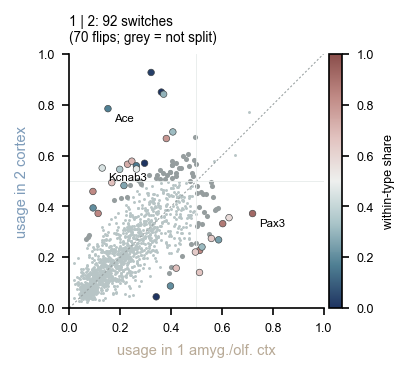

In [18]:
SWITCH_EX = [("Kcnab3", "ENSMUST00000018614"), ("Pax3", "ENSMUST00000172555"), ("Ace", "ENSMUST00000001964")]
Se = S[(S.reads_2 >= 100) & (S.reads_3 >= 100)]; sw = Se[Se.switch]; has = sw.within_frac.notna()
fig, ax = plt.subplots(figsize=(2.4, 2.2))
ax.scatter(Se.usage_2, Se.usage_3, s=2, lw=0, color=LIGHT, rasterized=True)
ax.plot([0, 1], [0, 1], color=GREY, lw=0.5, ls=(0, (2, 2)))
ax.axhline(0.5, color=MIST, lw=0.4); ax.axvline(0.5, color=MIST, lw=0.4)
ax.scatter(sw.usage_2[~has], sw.usage_3[~has], s=6, lw=0, color=GREY)
sc = ax.scatter(sw.usage_2[has], sw.usage_3[has], s=10, lw=0.3, edgecolor=INK, c=sw.within_frac[has].clip(0, 1), cmap=CMAP["score"], vmin=0, vmax=1, zorder=3)
for g, iso in SWITCH_EX:
    r = Se[Se.isoform == iso]
    ax.annotate(g, (r.usage_2.iloc[0], r.usage_3.iloc[0]), fontsize=5.5, style="italic", xytext=(3, -6), textcoords="offset points")
fig.colorbar(sc, ax=ax, fraction=0.05, pad=0.02).set_label("within-type share", fontsize=6)
ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.set_aspect("equal")
ax.set_xlabel(f"usage in {KA} amyg./olf. ctx", color=DOMAIN["amygdala / olfactory cortex"]); ax.set_ylabel(f"usage in {KC} cortex", color=DOMAIN["cortex"])
ax.set_title(f"{KA} | {KC}: {len(sw)} switches\n({int(sw.flip.sum())} flips; grey = not split)", loc="left", fontsize=6.5)
plt.show()

### Fig. 4j: switches across the boundary

Usage of Kcnab3 018614, Pax3 172555 and Ace 001964 in 10 equal-count `rho` bins per domain with the per-domain binomial fit (`fit_binomial`), on a rank scale of `rho`
because the amygdala / olfactory domain spans a short stretch of the axis.

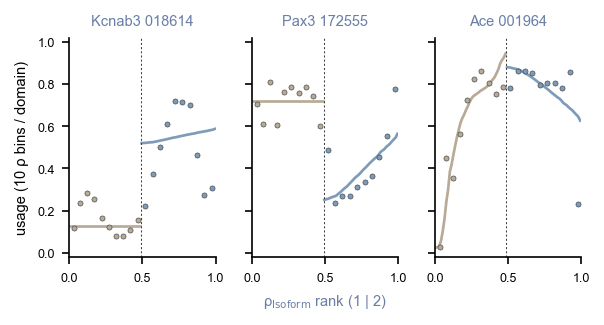

In [19]:
fig, AX = plt.subplots(1, 3, figsize=(4.4, 1.9), sharey=True, gridspec_kw=dict(wspace=0.25))
cl = dcol("Isoform"); w_ = np.sort(d_I[ma | mc]); rk = lambda v: np.searchsorted(w_, v) / len(w_)
for ax, (g, iso) in zip(AX, SWITCH_EX):
    s_ = counts_I[:, np.where(iso_name == iso)[0][0]].toarray().ravel()
    n_ = np.asarray(counts_I[:, np.where(iso_gene == g)[0]].sum(1)).ravel()
    sl, it = (v[0] for v in pw.fit_binomial(s_[:, None], n_, lab_I, d_I, t=0.1))
    for k in (KA, KC):
        m = np.where(lab_I == k)[0]; x = d_I[m]
        q = np.quantile(x, np.linspace(0, 1, 11)); bi = np.clip(np.digitize(x, q[1:-1]), 0, 9)
        xb = np.array([x[bi == b].mean() for b in range(10)]); nb_ = np.array([n_[m][bi == b].sum() for b in range(10)])
        ub = np.array([s_[m][bi == b].sum() for b in range(10)]) / np.maximum(nb_, 1)
        ax.scatter(rk(xb[nb_ >= 15]), ub[nb_ >= 15], s=6, color=cl[k], lw=0.3, edgecolor=INK, zorder=3)
        xs = np.quantile(x, np.linspace(0.01, 0.99, 40)); ax.plot(rk(xs), sigmoid(it[k] + sl[k] * xs), color=cl[k], lw=1.3)
    ax.axvline(ma.sum() / len(w_), color=INK, lw=0.5, ls=(0, (2, 2)))
    ax.set_ylim(-0.02, 1.02); ax.set_xlim(0, 1); ax.set_xticks([0, 0.5, 1])
    ax.set_title(f"{g} {iso[-6:]}", color=C_ISO)
AX[0].set_ylabel("usage (10 ρ bins / domain)"); AX[1].set_xlabel(f"ρ$_{{\\mathrm{{Isoform}}}}$ rank ({KA} | {KC})", color=C_ISO)
plt.show()

### Fig. 4k: composition or within cell type for the top switches

Usage change across the boundary for the 12 strongest switches split into composition and within-cell-type parts (with the 95% bootstrap interval of the within part),
and usage in neurons alone on each side.

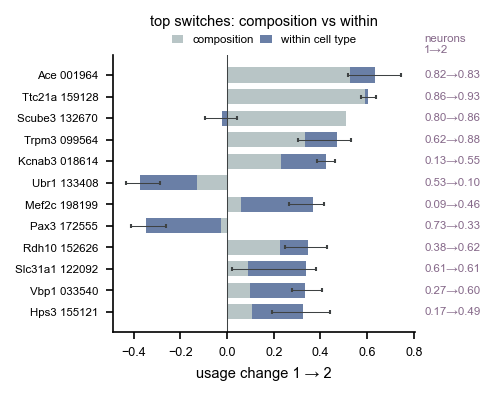

In [20]:
Sj = S[S.switch & S.within_frac.notna()].head(12).iloc[::-1]
y = np.arange(len(Sj)); left = np.where(np.sign(Sj.within) == np.sign(Sj.composition), Sj.composition, 0)
fig, ax = plt.subplots(figsize=(2.6, 2.4))
ax.barh(y, Sj.composition, color=LIGHT, height=0.7, label="composition")
ax.barh(y, Sj.within, left=left, color=C_ISO, height=0.7, label="within cell type")
ax.errorbar(left + Sj.within, y, xerr=[Sj.within - Sj.within_ci_lo, Sj.within_ci_hi - Sj.within], fmt="none", ecolor=INK, elinewidth=0.5, capsize=1)
for yy, (_, r) in zip(y, Sj.iterrows()):
    ax.text(1.03, yy, f"{r.neuron_usage_2:.2f}→{r.neuron_usage_3:.2f}", transform=ax.get_yaxis_transform(), fontsize=5.5, va="center", color=CELLCLASS["neuron"])
ax.text(1.03, 1.0, f"neurons\n{KA}→{KC}", transform=ax.transAxes, fontsize=5.5, va="bottom", color=CELLCLASS["neuron"])
ax.axvline(0, color=INK, lw=0.5)
ax.set_yticks(y); ax.set_yticklabels([f"{g} {i[-6:]}" for g, i in zip(Sj.gene, Sj.isoform)], fontsize=5.5, style="italic")
ax.set_xlabel(f"usage change {KA} → {KC}")
ax.legend(fontsize=5.5, loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=2, handlelength=1.0, columnspacing=0.6)
ax.set_title("top switches: composition vs within", pad=14)
plt.show()

## Sst interneurons across the boundary

Sst interneurons sit on both sides of the boundary, so a change of usage inside this one type cannot come from composition. The
section is adult tissue, so this is a spatial continuum of states inside the type, not a time course.

The RNA state score `t` of each Sst cell is the probability that its expression belongs to the cortex side: a logistic
regression of cortex vs amygdala / olfactory domain on a scVI latent space of the Sst cells (1,000 variable genes, 10 latent
dimensions, seed 42), out-of-fold (5-fold) for the cells of these two domains. scVI ran in the `tutorial_lpc` env and the score,
a diffusion pseudotime and CellRank 2 macrostates in the `stories` env (`reproducibility/paper/scripts/rtt_sst_isoform_transition.py`,
steps `scvi` and `cellrank`); the per-cell table is read from `published/`.

In [21]:
sel = np.where((cell_type == "Inhibitory_Sst") & (cell_bin >= 0))[0]
states = pd.read_csv(PUB / "sst_states.csv", index_col=0).loc[[f"sst_{i}" for i in sel]]
t = states.t_state.values
dom = lab_I[cell_bin[sel]]
pair_side = np.isin(dom, [KA, KC])
transitional = (t >= 0.25) & (t <= 0.75)
cv_auc = roc_auc_score((dom[pair_side] == KC).astype(int), t[pair_side])
t_vs_rho = spearmanr(t, d_I[cell_bin[sel]]).statistic
dpt_vs_rho = spearmanr(states.dpt_pseudotime, d_I[cell_bin[sel]]).statistic
print(f"{len(sel)} Sst cells, per domain {np.bincount(dom).tolist()}; CV AUC {cv_auc:.3f}; Spearman with rho_Isoform: t {t_vs_rho:.3f}, "
      f"DPT {dpt_vs_rho:.3f}; transitional {transitional.sum()}")

594 Sst cells, per domain [100, 200, 294]; CV AUC 0.925; Spearman with rho_Isoform: t 0.476, DPT 0.151; transitional 151


### Fig. 4l: Sst interneurons by RNA state score

The 594 Sst interneurons coloured by `t`; open circles mark transitional cells (0.25 <= t <= 0.75).

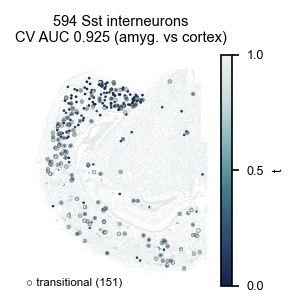

In [22]:
fig, ax = plt.subplots(figsize=(2.2, 2.0))
ax.scatter(*cell_xy.T, s=0.05, lw=0, color=MIST, rasterized=True)
o = np.argsort(t)
sc = ax.scatter(*cell_xy[sel][o].T, c=t[o], cmap=CMAP["pseudotime"], vmin=0, vmax=1, s=1.6, lw=0, rasterized=True)
ax.scatter(*cell_xy[sel][transitional].T, s=3.2, facecolor="none", edgecolor=INK, lw=0.2, rasterized=True)
map_axes(ax)
fig.colorbar(sc, ax=ax, fraction=0.05, pad=0.02, ticks=[0, 0.5, 1]).set_label("t", fontsize=6)
ax.set_title(f"{len(sel)} Sst interneurons\nCV AUC {cv_auc:.3f} (amyg. vs cortex)")
ax.text(0.0, 0.0, f"○ transitional ({transitional.sum()})", transform=ax.transAxes, fontsize=5.5)
plt.show()

### Fig. 4m: state score per domain

`t` of the Sst cells in each `rho_Isoform` domain (mean as a black line); the shaded band is the transitional range. The title gives the Spearman correlation of `t` and of the
RNA-only diffusion pseudotime with `rho_Isoform`.

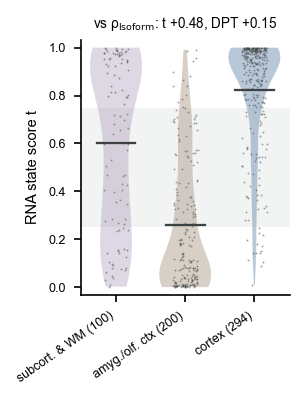

In [23]:
fig, ax = plt.subplots(figsize=(1.8, 2.2))
rj = np.random.default_rng(0)
for k in range(lab_I.max() + 1):
    v = t[dom == k]; col = DOMAIN[NAMES["Isoform"][k]]
    vp = ax.violinplot(v, [k], widths=0.75, showextrema=False)
    for b in vp["bodies"]:
        b.set_facecolor(col); b.set_edgecolor("none"); b.set_alpha(0.55)
    ax.scatter(k + rj.uniform(-0.18, 0.18, len(v)), v, s=0.8, lw=0, color=INK, alpha=0.5, rasterized=True)
    ax.plot([k - 0.28, k + 0.28], [v.mean()] * 2, color=INK, lw=1.1)
ax.axhspan(0.25, 0.75, color=GREY, alpha=0.12, lw=0)
ax.set_xticks(range(lab_I.max() + 1))
ax.set_xticklabels([f"{SHORT[NAMES['Isoform'][k]]} ({(dom == k).sum()})" for k in range(lab_I.max() + 1)], rotation=35, ha="right")
ax.set_ylim(-0.03, 1.03); ax.set_ylabel("RNA state score t")
ax.set_title(f"vs ρ$_{{\\mathrm{{Isoform}}}}$: t {t_vs_rho:+.2f}, DPT {dpt_vs_rho:+.2f}", fontsize=6.5)
plt.show()

### Isoform usage along t

Every non-major isoform of the selected genes with at least 80 reads in Sst cells (and 5% of its gene's reads) is tested with a
binomial GLM of usage on `t` at cell level. The null permutes `t` across cells 500 times (BH over isoforms); a second test adds
the domain as a covariate and permutes `t` within domains, asking whether usage follows the RNA state beyond the cell's
location. The switch point `t0` comes from a 4-parameter sigmoid fitted by binomial maximum likelihood to usage in 10 quantile
windows of `t`. Isoforms whose gene is expressed in Sst cells at less than 0.3 times the level of the 10 nearest other neurons
are flagged as possible spillover. A switch has q < 0.1, a usage change of at least 0.15 and no spillover flag.

In [24]:
Xi_sst = X_iso[sel].tocsc()
tot_sst = np.asarray(Xi_sst.sum(0)).ravel()
rows = []
for g, idx in pd.Series(np.arange(len(iso_gene))).groupby(iso_gene):
    if g not in sv_genes:
        continue
    idx = idx.values[np.argsort(-tot_sst[idx.values])]
    if tot_sst[idx].sum() < 150:
        continue
    rows += [(g, iso_name[j], j, idx) for j in idx[1:] if tot_sst[j] >= 80 and tot_sst[j] / tot_sst[idx].sum() >= 0.05]
As = np.column_stack([Xi_sst[:, j].toarray().ravel() for _, _, j, _ in rows]).astype(float)
Ns = np.column_stack([np.asarray(Xi_sst[:, ix].sum(1)).ravel() for *_, ix in rows]).astype(float)

if not (OUT / "sst_null.npz").exists():
    one_s = np.ones(len(t)); tz = (t - t.mean()) / t.std()
    Dm = np.c_[[(dom == k).astype(float) for k in sorted(set(dom))[1:]]].T
    b, dev1 = binom_irls(As, Ns, np.c_[one_s, tz]); _, dev0 = binom_irls(As, Ns, one_s[:, None])
    bw, _ = binom_irls(As, Ns, np.c_[one_s, tz, Dm])
    rng = np.random.default_rng(42)
    null = np.array([binom_irls(As, Ns, np.c_[one_s, rng.permutation(tz)])[0][:, 1] for _ in range(500)])
    null_w = []
    for _ in range(500):
        tp = tz.copy()
        for k in set(dom):
            ii = np.where(dom == k)[0]; tp[ii] = rng.permutation(tz[ii])
        null_w.append(binom_irls(As, Ns, np.c_[one_s, tp, Dm])[0][:, 1])
    np.savez(OUT / "sst_null.npz", b=b, dev1=dev1, dev0=dev0, bw=bw, null=null, null_w=np.array(null_w))
R_ = np.load(OUT / "sst_null.npz")


def sigmoid4(a_, n_, t_, w=10):
    """4-parameter sigmoid of usage in w quantile windows of t, binomial ML: low, high, steepness, t0, window usage"""
    q = np.quantile(t_, np.linspace(0, 1, w + 1)); bi = np.clip(np.digitize(t_, q[1:-1]), 0, w - 1)
    tw = np.array([t_[bi == k].mean() for k in range(w)])
    aw = np.array([a_[bi == k].sum() for k in range(w)]); nw = np.array([n_[bi == k].sum() for k in range(w)])
    uw = aw / np.maximum(nw, 1)

    def nll(p):
        lo, hi = sigmoid(p[0]), sigmoid(p[1])
        u = np.clip(lo + (hi - lo) / (1 + np.exp(-np.exp(p[2]) * (tw - p[3]))), 1e-6, 1 - 1e-6)
        return -(aw * np.log(u) + (nw - aw) * np.log(1 - u)).sum()
    start = [np.log((uw[0] + .02) / (1.02 - uw[0])), np.log((uw[-1] + .02) / (1.02 - uw[-1])), np.log(8)]
    best = min((minimize(nll, start + [t0], method="Nelder-Mead", options=dict(maxiter=4000, xatol=1e-5, fatol=1e-7)) for t0 in (0.25, 0.5, 0.75)),
               key=lambda r: r.fun)
    return sigmoid(best.x[0]), sigmoid(best.x[1]), float(np.exp(best.x[2])), float(np.clip(best.x[3], -0.2, 1.2)), uw


# spillover control: expression of the gene in Sst cells vs in their 10 nearest non-Sst neurons
pool = np.where(neuron & (cell_type != "Inhibitory_Sst"))[0]
nbr = pool[cKDTree(cell_xy[pool]).query(cell_xy[sel], k=10)[1]]
Gn = sp.csr_matrix((np.ones(nbr.size), (np.repeat(np.arange(len(sel)), 10), nbr.ravel())), shape=(len(sel), len(cell_type)))
Xg_sst, Xg_nbr = sp.csc_matrix(X_gene[sel]), sp.csc_matrix(Gn @ X_gene)
lib_sst, lib_nbr = Xg_sst.sum(), Xg_nbr.sum()


def expr_ratio(g):
    j = list(genes).index(g) if g in genes else -1
    return np.nan if j < 0 else (Xg_sst[:, j].sum() / lib_sst) / max(Xg_nbr[:, j].sum() / lib_nbr, 1e-12)


b, bw, null, null_w = R_["b"], R_["bw"], R_["null"], R_["null_w"]
Tsst = pd.DataFrame(dict(gene=[r[0] for r in rows], isoform=[r[1] for r in rows], reads=As.sum(0), usage=As.sum(0) / Ns.sum(0),
                         slope_per_sd=b[:, 1], dev_expl=1 - R_["dev1"] / R_["dev0"],
                         p_perm=((np.abs(null) >= np.abs(b[:, 1])).sum(0) + 1) / 501, p_within_dom=((np.abs(null_w) >= np.abs(bw[:, 1])).sum(0) + 1) / 501))
Tsst["q"] = multipletests(Tsst.p_perm, method="fdr_bh")[1]
Tsst["q_within_dom"] = multipletests(Tsst.p_within_dom, method="fdr_bh")[1]
sg = [sigmoid4(As[:, i], Ns[:, i], t) for i in range(As.shape[1])]
Tsst["u_lo"], Tsst["u_hi"], Tsst["steep"], Tsst["t0"] = ([v[k] for v in sg] for k in range(4))
Tsst["uw"] = [v[4] for v in sg]
Tsst["du"] = Tsst.u_hi - Tsst.u_lo
Tsst["expr_ratio_sst_vs_nbr"] = [expr_ratio(g) for g in Tsst.gene]
Tsst["switch"] = (Tsst.q < 0.1) & (Tsst.du.abs() >= 0.15) & ~(Tsst.expr_ratio_sst_vs_nbr < 0.3)
Tsst["state_coupled"] = Tsst.switch & (Tsst.q_within_dom < 0.1)
Tsst = Tsst.sort_values("q")
print(f"{len(Tsst)} isoforms tested; q < 0.1: {(Tsst.q < 0.1).sum()}; switches {Tsst.switch.sum()}; hold within domain {Tsst.state_coupled.sum()}")
Tsst.drop(columns="uw").head(6).round(3)

26 isoforms tested; q < 0.1: 3; switches 3; hold within domain 1


,gene,isoform,reads,usage,slope_per_sd,dev_expl,p_perm,p_within_dom,q,q_within_dom,u_lo,u_hi,steep,t0,du,expr_ratio_sst_vs_nbr,switch,state_coupled
11,Kcnab3,ENSMUST00000142328,148.0,0.471,-0.765,0.095,0.002,0.002,0.026,0.052,0.681,0.262,18.508,0.815,-0.419,0.927,True,True
24,Vbp1,ENSMUST00000033540,80.0,0.497,0.711,0.086,0.002,0.108,0.026,0.374,0.330,0.754,149.329,0.767,0.424,1.491,True,False
6,Coq8b,ENSMUST00000003860,156.0,0.359,0.322,0.019,0.004,0.431,0.035,0.701,0.287,0.480,26.895,0.844,0.193,0.784,True,False
1,Acbd3,ENSMUST00000027780,115.0,0.464,0.323,0.021,0.018,0.188,0.117,0.443,0.387,0.589,32.830,0.692,0.201,1.368,False,False
15,Ntm,ENSMUST00000115237,124.0,0.103,-0.235,0.007,0.034,0.309,0.126,0.623,0.512,0.092,10.854,-0.077,-0.420,NaN,False,False
12,Kcnc1,ENSMUST00000025202,146.0,0.264,-0.246,0.008,0.028,0.515,0.126,0.788,0.357,0.236,302.440,0.523,-0.121,NaN,False,False


### Fig. 4n: usage in Sst cells along t

Usage in Sst cells in 10 quantile windows of `t` for the three switches, with the four-parameter sigmoid and its switch point
`t0` (red dashed line); the grey band is the transitional range. Titles give q from permutations across cells and within domains
(blue title = holds within domain).

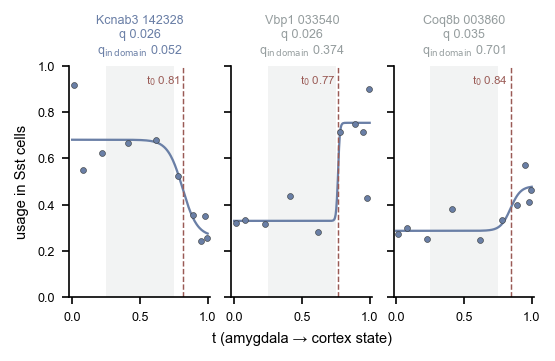

In [25]:
SW = [("Kcnab3", "ENSMUST00000142328"), ("Vbp1", "ENSMUST00000033540"), ("Coq8b", "ENSMUST00000003860")]
q_ = np.quantile(t, np.linspace(0, 1, 11)); bi = np.clip(np.digitize(t, q_[1:-1]), 0, 9)
tw = np.array([t[bi == k].mean() for k in range(10)]); xs = np.linspace(0, 1, 200)
fig, AX = plt.subplots(1, 3, figsize=(4.0, 2.0), sharey=True, gridspec_kw=dict(wspace=0.15))
for ax, (g, iso) in zip(AX, SW):
    r = Tsst[Tsst.isoform == iso].iloc[0]
    ax.axvspan(0.25, 0.75, color=GREY, alpha=0.12, lw=0)
    ax.scatter(tw, r.uw, s=8, color=C_ISO, lw=0.3, edgecolor=INK, zorder=3)
    ax.plot(xs, r.u_lo + (r.u_hi - r.u_lo) / (1 + np.exp(-r.steep * (xs - r.t0))), color=C_ISO, lw=1.1)
    ax.axvline(r.t0, color=RUST, lw=0.7, ls="--")
    ax.text(r.t0 - 0.02, 0.97, f"t$_0$ {r.t0:.2f}", color=RUST, fontsize=5.5, ha="right", va="top")
    ax.set_ylim(0, 1); ax.set_xlim(-0.02, 1.02); ax.set_xticks([0, 0.5, 1])
    ax.set_title(f"{g} {iso[-6:]}\nq {r.q:.3f}\nq$_{{\\mathrm{{in\\,domain}}}}$ {r.q_within_dom:.3f}", fontsize=6,
                 color=C_ISO if r.state_coupled else GREY)
AX[0].set_ylabel("usage in Sst cells"); AX[1].set_xlabel("t (amygdala → cortex state)")
plt.show()

### Fig. 4o: all testable isoforms

Usage change along `t` for the 26 testable isoforms against the permutation q; the dotted line is q = 0.1, switches are blue and
the red circle marks the switch that holds within domains.

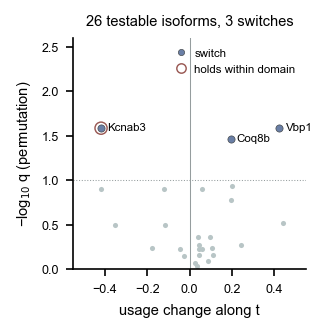

In [26]:
fig, ax = plt.subplots(figsize=(2.0, 2.0))
yq = -np.log10(Tsst.q.clip(1e-3)); swm = Tsst.switch.values; scm = Tsst.state_coupled.values
ax.scatter(Tsst.du[~swm], yq[~swm], s=6, color=LIGHT, lw=0)
ax.scatter(Tsst.du[swm], yq[swm], s=12, color=C_ISO, lw=0.3, edgecolor=INK, zorder=3)
ax.scatter(Tsst.du[scm], yq[scm], s=34, facecolor="none", edgecolor=RUST, lw=0.7, zorder=4)
for _, r in Tsst[swm].iterrows():
    ax.annotate(r.gene, (r.du, -np.log10(max(r.q, 1e-3))), fontsize=5.5, style="italic", xytext=(3, -1), textcoords="offset points")
ax.axhline(-np.log10(0.1), color=GREY, lw=0.5, ls=":"); ax.axvline(0, color=GREY, lw=0.5)
ax.set_xlabel("usage change along t"); ax.set_ylabel("−log$_{10}$ q (permutation)")
ax.set_xlim(-0.55, 0.55); ax.set_ylim(0, 2.6)
ax.set_title(f"{len(Tsst)} testable isoforms, {int(swm.sum())} switches")
ax.legend(handles=[Line2D([], [], marker="o", ls="", color=C_ISO, mec=INK, mew=0.3, ms=3, label="switch"),
                   Line2D([], [], marker="o", ls="", mfc="none", mec=RUST, mew=0.7, ms=4.5, label="holds within domain")],
          fontsize=5.5, loc="upper right", handletextpad=0.2)
plt.show()

## Saved tables

The tables behind panels f, h to k and n, o are written to `OUT`.

In [27]:
whole.to_csv(OUT / "composition_vs_within.csv", index=False)
slopes.to_csv(OUT / "domain_slopes.csv", index=False)
S.to_csv(OUT / "switch_23.csv", index=False)
Tsst.assign(uw=[";".join(f"{v:.3f}" for v in u) for u in Tsst.uw]).to_csv(OUT / "isoform_dynamics.csv", index=False)
pd.DataFrame({"x": coords[:, 0], "y": coords[:, 1], "d_RNA": d_R, "d_Isoform": d_I, "domain_RNA": lab_R, "domain_Isoform": lab_I}).to_csv(OUT / "axes.csv")
print(sorted(p.name for p in OUT.iterdir()))

['axes.csv', 'axes.npy', 'composition_vs_within.csv', 'domain_slopes.csv', 'isoform_dynamics.csv', 'r2.json', 'sst_null.npz', 'switch_23.csv']
